# Group Project Cryosphere

Earth Observation group project about a glacier in the Himalaya in Nepal. We try to measure glacier area, surface temperature variation, and wet/total snow area using satellite data from Google Earth Engine. We investigate these aspects on the time series of 2015 - 2026.

## Initializing

In [1]:
import ee
import os
import time
import geemap
import rasterio
import rasterio
import numpy as np
import pandas as pd
import plotting as pl
import gst_series as gs
import sar_snow as ss
import gst_pixel as gp
import glacier_area as ga
import gst_line as gl
import io_param_functions as ipf

In [ ]:
# run once at beginning, supply token
ee.Authenticate()
GEE_PROJECT = "my-hello-world-508910"  # replace with your own project id
ee.Initialize(project=GEE_PROJECT)

In [ ]:
ROI = [[81.768322, 30.198924], [81.785316, 30.200185], [81.782656, 30.20241], [81.780596, 30.2079], [81.780252, 30.215613], [81.780424, 30.223327], [81.778965, 30.228741], [81.776733, 30.231707], [81.774759, 30.231781], [81.771927, 30.225403], [81.77021, 30.216503], [81.770382, 30.211237], [81.770296, 30.206416], [81.766691, 30.202707], [81.765575, 30.199962], [81.768322, 30.198924]]
AOI = ee.Geometry.Polygon(ROI)

In [4]:
START = "2014-09-01"
END = "2026-12-31"
YEARS = list(range(2015, 2027))

DEBUG = True
SAVE_PATH = "results"

In [5]:
glims = ee.FeatureCollection("GLIMS/current").filterBounds(AOI)
glacier_glims_geom = glims.geometry(1)  # ee.Geometry of the GLIMS outlines
Map = geemap.Map(basemap="HYBRID")
Map.centerObject(AOI, 14)
Map.addLayer(ee.Image().paint(AOI, 1, 2), {"palette": ["red"]}, "AOI")
Map.addLayer(ee.Image().paint(glacier_glims_geom, 1, 2), {"palette": ["blue"]}, "Glims outline")
Map

Map(center=[30.212620057076144, 81.77534281078347], controls=(WidgetControl(options=['position', 'transparent_…

## Image Collections Analysis

Get a sense of how many Images we are working with, from what date they are and how much they are covered by clouds.

In [6]:
s2_toa = ee.ImageCollection("COPERNICUS/S2_HARMONIZED").filterBounds(AOI).sort("system:time_start").set("collection_name", "Sentinel 2 Top of Atmosphere")
s2_boa = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED").filterBounds(AOI).sort("system:time_start").set("collection_name", "Sentinel 2 Bottom of Atmosphere")

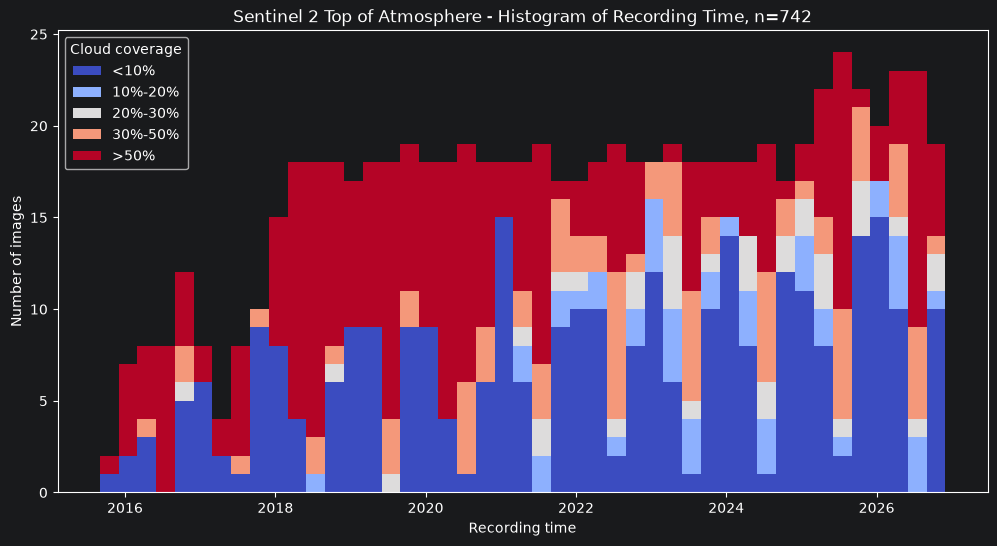

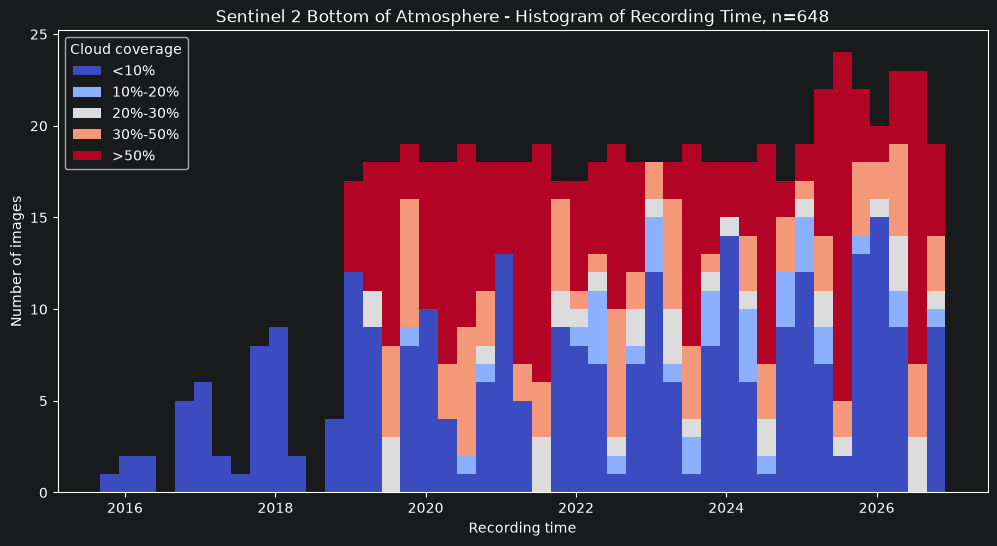

In [7]:
fig_s2_toa_obsv = pl.plot_histogram_image_collection(s2_toa, "2015-09-01", "2027-01-01")
fig_s2_boa_obsv = pl.plot_histogram_image_collection(s2_boa, "2015-09-01", "2027-01-01")

In these Histograms we see that there Sentinel 2 provides data with few clouds from 2016 to 2026. Also, we see that cloud cover is very seasonal. Especially in summer, images with cloud coverage <30% are scarce. Although more and more images are provided throughout the time period, image count has been very consistent since 2019.

## Snow/ice area

Sentinel 2 median -> NDSI -> greater than 0.4

In [6]:
masks = ga.download_snow_masks(AOI, YEARS, months=(7, 9), debug=False)
map_area = pl.plot_glacier_area_map(masks, AOI, glacier_glims_geom)
map_area

Map(center=[30.212620057076144, 81.77534281078347], controls=(WidgetControl(options=['position', 'transparent_…

In [5]:
season_df = ga.area_by_season(AOI, YEARS, debug=False)  # glacier_mask=glacier_mask restricts to GLIMS
ipf.save_any_tables_and_figures({"area_by_season": season_df}, save_path=os.path.join(SAVE_PATH, "glacier_area"))

2015-01-01 .. 2015-03-31: 0 scenes
Jan - Mar 2015: None
2016-01-01 .. 2016-03-31: 3 scenes
Jan - Mar 2016: 2.9222647417350007
2017-01-01 .. 2017-03-31: 5 scenes
Jan - Mar 2017: 3.1823793415065382
2018-01-01 .. 2018-03-31: 9 scenes
Jan - Mar 2018: 2.5279913264752554
2019-01-01 .. 2019-03-31: 9 scenes
Jan - Mar 2019: 3.410469948894543
2020-01-01 .. 2020-03-31: 7 scenes
Jan - Mar 2020: 3.4408053328755663
2021-01-01 .. 2021-03-31: 11 scenes
Jan - Mar 2021: 2.727027642566756
2022-01-01 .. 2022-03-31: 13 scenes
Jan - Mar 2022: 3.441038945843383
2023-01-01 .. 2023-03-31: 17 scenes
Jan - Mar 2023: 3.3319479545729673
2024-01-01 .. 2024-03-31: 15 scenes
Jan - Mar 2024: 2.2936761559206484
2025-01-01 .. 2025-03-31: 16 scenes
Jan - Mar 2025: 3.2002464459841247
2026-01-01 .. 2026-03-31: 19 scenes
Jan - Mar 2026: 2.5682271330437163
2015-04-01 .. 2015-06-30: 0 scenes
Apr - Jun 2015: None
2016-04-01 .. 2016-06-30: 1 scenes
Apr - Jun 2016: 3.3703996947548034
2017-04-01 .. 2017-06-30: 2 scenes
Apr - Jun 

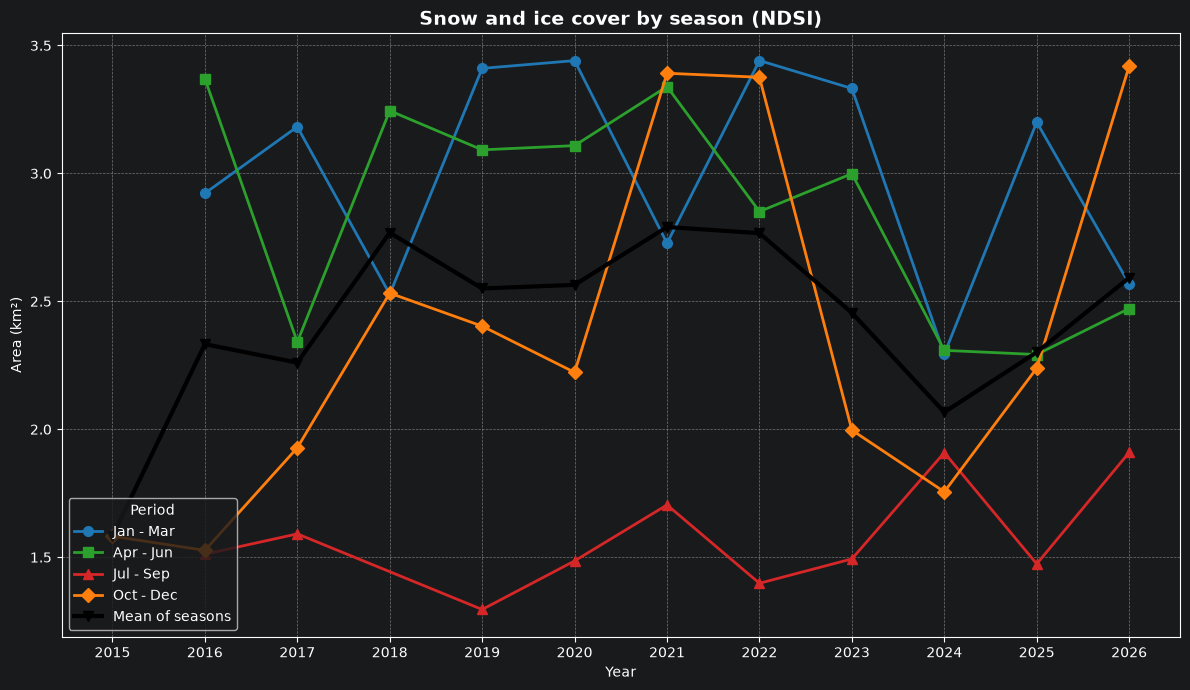

In [6]:
fig_seasons = pl.plot_glacier_area_seasons(season_df)

In [ ]:
month_df = ga.area_by_month(AOI, 2021, debug=DEBUG)

In [ ]:
fig_months = pl.plot_glacier_area_months(month_df, 2021)

## Surface temperature variation

### GST series

In [14]:
glacier_mask, mask_status = gs.get_glacier_mask(roi=AOI)
print("Glacier mask source:", mask_status)

Glacier mask source: GLIMS/current outlines


In [13]:
dem = ee.Image("USGS/SRTMGL1_003").select("elevation")
bin_img = gs.get_dem_bins(dem) # 50 bzw. BIN_M grosse Höhenstufen
# Map = pl.show_dem_map(dem=dem, roi=AOI, glacier_mask=glacier_mask) # needs debugging / checking!

In [ ]:
raw_gst = gs.download(bin_img, glacier_mask, AOI, START, END, debug=False)
gst_half_month = gs.process(raw_gst, debug=True)
ablation_trend = gs.ablation_trend(gst_half_month, debug=True)
gst_half_month.head()

In [ ]:
fig_gst_observations_1 = pl.plot_half_months(gst_half_month)
fig_gst_observations_2 = pl.plot_half_months_2(gst_half_month)
fig_gst_observations_2.show()

In [ ]:
fig_gst_err = pl.plot_gst_series(gst_half_month, errorbars=True)
fig_gst_noerr = pl.plot_gst_series(gst_half_month, errorbars=False)
fig_gst_noerr.show()

In [ ]:
ipf.save_any_tables_and_figures(
    {"gst_raw_scene_bins": raw_gst,
     "gst_halfmonthly": gst_half_month,
     "gst_ablation_season": ablation_trend,
     "gst_obervations_1": fig_gst_observations_1,
     "gst_obervations_2": fig_gst_observations_2,
     "gst_err": fig_gst_err,
     "gst_noerr": fig_gst_noerr},
    save_path="results/gst_series/"
)

### GST per pixel

In [ ]:
scenes = gp.download_zone_scenes(AOI, glacier_mask, START, END, debug=True)
half_monthly = gp.process_zones(scenes, debug=True)

winters = gp.winter_means(half_monthly)
print(gp.winter_trends(winters).round(3))

In [ ]:
pixel_arrays = gp.image_to_arrays(gp.pixel_statistics(AOI, glacier_mask, START, END), AOI)
fig = pl.plot_pixel_maps(pixel_arrays)
fig.show()

In [ ]:
point_series_df = gp.download_point_series({"centre": (81.774, 30.220)}, START, END, debug=True)

In [ ]:
ipf.save_any_tables_and_figures(
    {"gst_scene_zone_sums": scenes,
     "gst_halfmonthly_winter": half_monthly,
     "gst_winter_means": winters,
     "gst_points": point_series_df,
     "gst_pixel_maps": fig},
    save_path = "results/gst_pixel/"
)

### GST Line

In [15]:
lst = gl.download_lst(AOI, "2014-09-01", "2026-12-31", max_cloud=60, debug=DEBUG)
stack = gl.season_stack(lst, AOI)
n_season = gl.season_count(lst, debug=DEBUG)

NameError: name 'gl' is not defined

## Wet/total snow area

In [ ]:
df, bdf = ss.all_stats(AOI, "2014-09-01", "2026-12-31", glacier_mask=glacier_mask, debug=True)

In [7]:
SY = 2024
ORBIT = "ASCENDING"
MONTHS = (12, *range(1, 7))

DAY_TICKS_ALL = ([32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335, 0],
                 ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])

day_ticks = ([DAY_TICKS_ALL[0][m - 1] for m in MONTHS],
             [DAY_TICKS_ALL[1][m - 1] for m in MONTHS])
print(day_ticks)

([0, 32, 60, 91, 121, 152, 182], ['Dec', 'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun'])


In [ ]:
monthly_table = ss.monthly_mean_table(df)

fig_snow_series = ss.plot_sar_snow_series(df)
fig_snow_season = ss.plot_sar_snow_season(df, day_ticks=day_ticks)

In [ ]:
ipf.save_any_tables_and_figures(
    {"snow_scenes": df,
     "snow_elev_bands": bdf,
     "monthly_table": monthly_table,
     "sar_snow_series": fig_snow_series,
     "sar_snow_season": fig_snow_season},
    save_path="results/sar_snow/",
)

In [ ]:
fig_snow_elev = ss.plot_sar_snow_elev(bdf, SY, ORBIT) # wet fraction by elevation band and date
fig_snow_diff_history = ss.show_sar_snow_diff_history(AOI, SY, ORBIT, months=(12, *range(1, 12))) # backscatter-change histogram per month, threshold marked
fig_snow_maps = ss.show_sar_snow_maps(AOI, SY, ORBIT, months=(12, *range(1, 12)), glacier_mask=glacier_mask) # monthly wet frequency and melt-onset day

In [ ]:
ipf.save_any_tables_and_figures(
    {f"sar_snow_elev_{SY}_{ORBIT}": fig_snow_elev,
     f"sar_snow_diff_history_{SY}_{ORBIT}": fig_snow_diff_history,
     f"sar_snow_maps_{SY}_{ORBIT}": fig_snow_maps},
    save_path="results/sar_snow/",
)